In [1]:
import sys
from pathlib import Path
# add ../scripts relative to the current notebook
scripts_path = Path(".") / "scripts"
sys.path.append(str(scripts_path))

In [2]:

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import box


In [3]:
from wms import (
    LAYER_RGB_125, LAYER_CIR500,
    INDEX_RGB_125, INDEX_CIR500,
    bbox_buffered, getmap_bytes, meta_at_point
)
from plots import plot_plate_1x3

In [4]:
# Reload modules to pick up changes
import importlib
import plots
importlib.reload(plots)
from plots import plot_plate_1x3

In [5]:
# Load data
squares = gpd.read_file("../data/annotations/sds.shp").to_crs(27700)
ann = gpd.read_file("../data/annotations/hab.shp").to_crs(27700)

/home/david/.local/lib/python3.10/site-packages/pyogrio/raw.py:200: RuntimeWarning: organizePolygons() received an unexpected geometry.  Either a polygon with interior rings, or a polygon with less than 4 points, or a non-Polygon geometry.  Return arguments as a collection.
  return ogr_read(
/home/david/.local/lib/python3.10/site-packages/pyogrio/raw.py:200: RuntimeWarning: Geometry of polygon of fid 212 cannot be translated to Simple Geometry. All polygons will be contained in a multipolygon.
  return ogr_read(
/home/david/.local/lib/python3.10/site-packages/pyogrio/raw.py:200: RuntimeWarning: Geometry of polygon of fid 213 cannot be translated to Simple Geometry. All polygons will be contained in a multipolygon.
  return ogr_read(


In [6]:
# Pick one square
sq = squares.iloc[0].geometry

# set bbox buffer for context
bbox = bbox_buffered(sq.bounds, 15)

# imagery
rgb125 = getmap_bytes(LAYER_RGB_125, bbox, width=1400)
cir500 = getmap_bytes(LAYER_CIR500, bbox, width=1400)
rgb_for_ann = rgb125  # panel 3 uses RGB again

# metadata at centroid
meta_rgb = meta_at_point(INDEX_RGB_125, sq.centroid)
meta_cir = meta_at_point(INDEX_CIR500, sq.centroid)

def fmt(meta):
    d = meta.date_flown.date().isoformat() if pd.notna(meta.date_flown) else "No data"
    return f"{meta.kmreference or ''} | {d}"


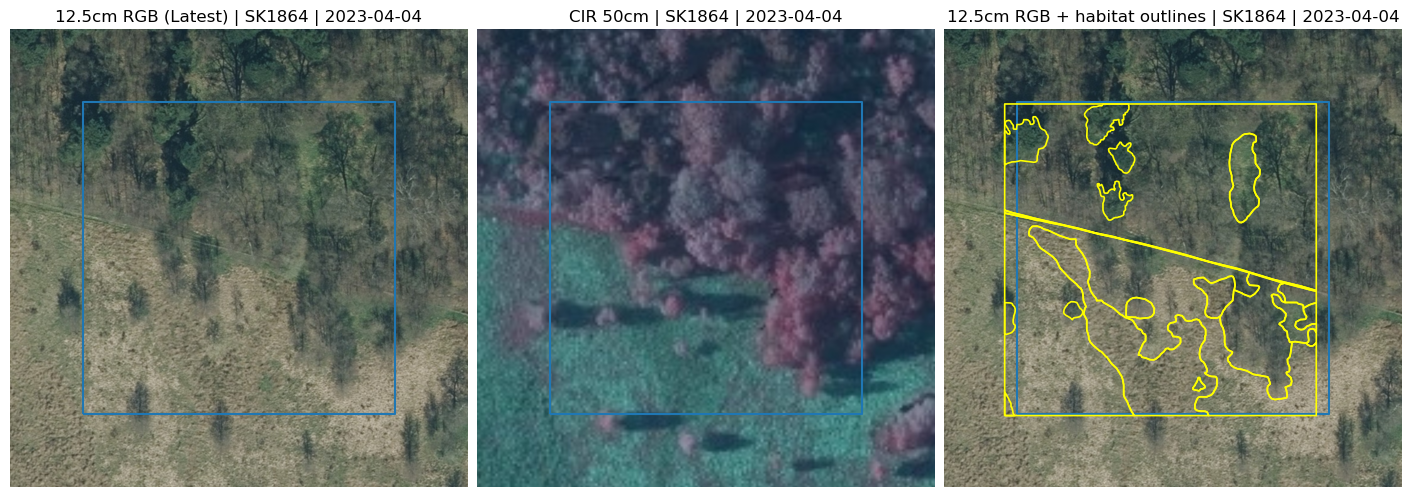

In [7]:
fig = plot_plate_1x3(
    bbox=bbox,
    rgb125_bytes=rgb125,
    cir500_bytes=cir500,
    rgb_anno_bytes=rgb_for_ann,

    sample_geom=sq,
    annotations=ann,
    draw_labels=False,  # <-- no labels
    title1=f"12.5cm RGB (Latest) | {fmt(meta_rgb)}",
    title2=f"CIR 50cm | {fmt(meta_cir)}",
    title3=f"12.5cm RGB + habitat outlines | {fmt(meta_rgb)}",
)
plt.show()

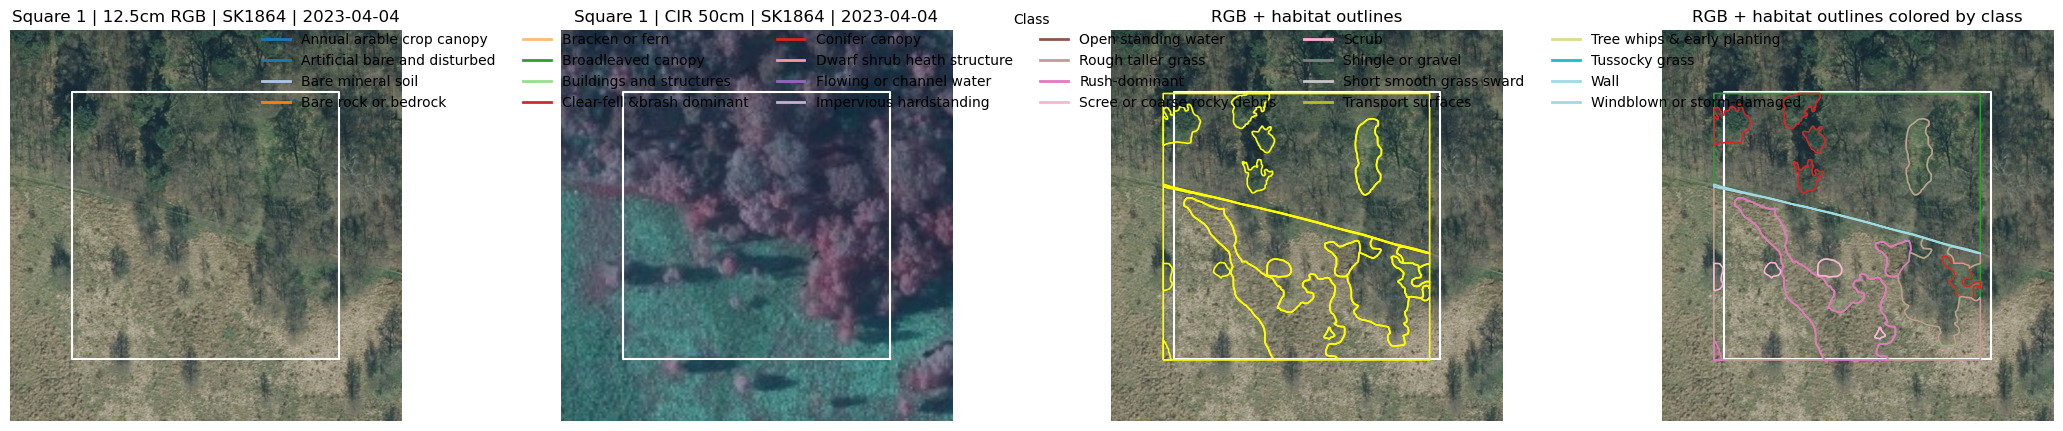

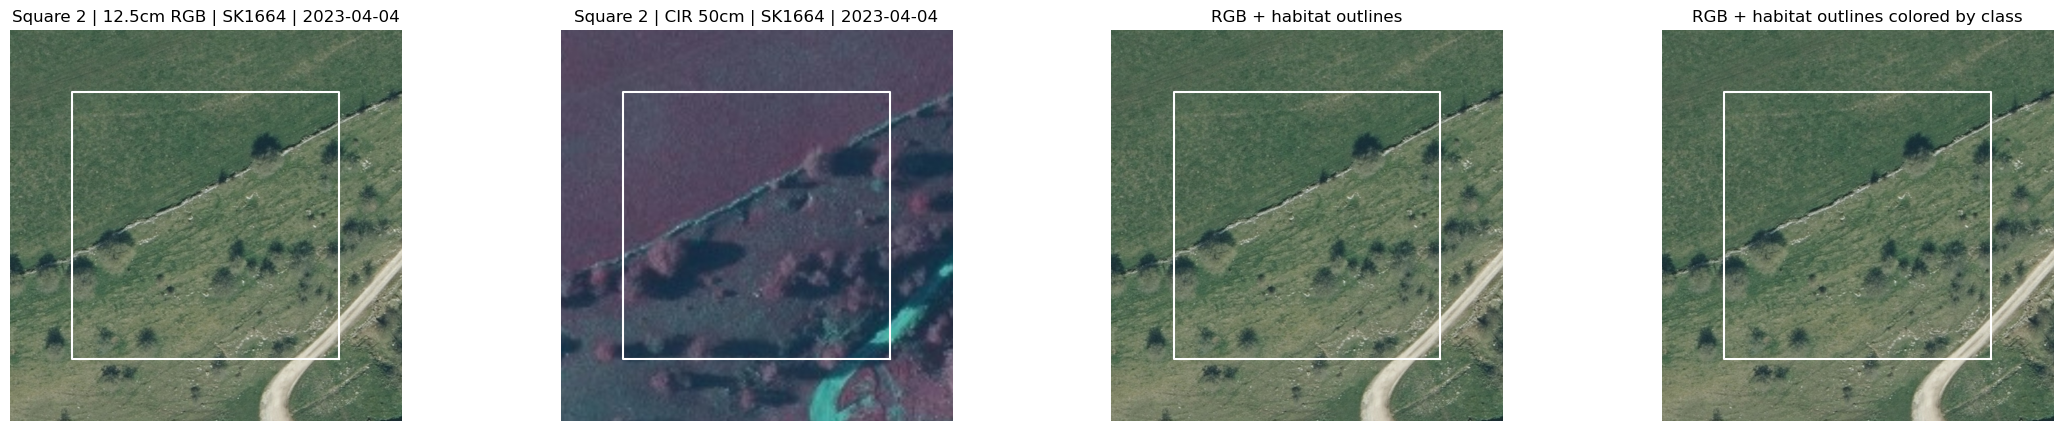

KeyboardInterrupt: 

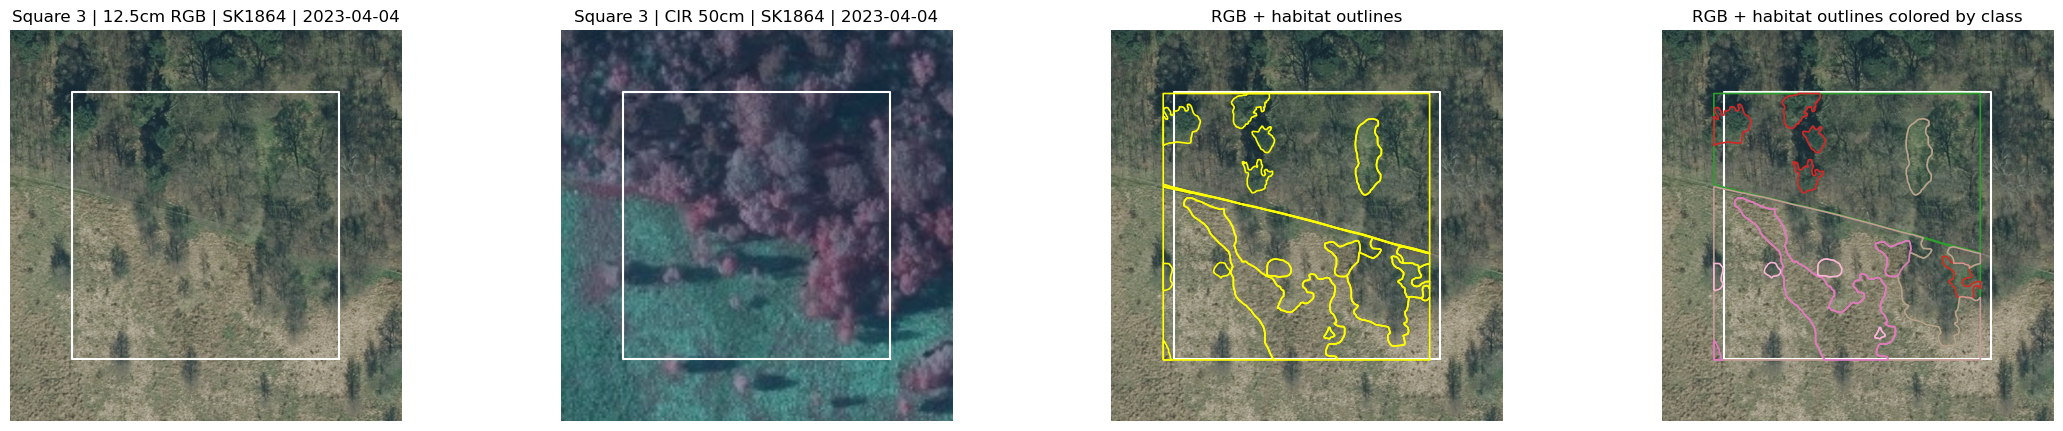

In [ ]:
import io
import numpy as np
from matplotlib.lines import Line2D


def _fmt(meta):
    d = meta.date_flown.date().isoformat() if pd.notna(meta.date_flown) else "No data"
    return f"{meta.kmreference or ''} | {d}"


def _imshow_bytes(ax, img_bytes, bbox):
    img = plt.imread(io.BytesIO(img_bytes))
    extent = (bbox[0], bbox[2], bbox[1], bbox[3])
    ax.imshow(img, extent=extent)
    ax.set_axis_off()


def _draw_geom_boundary(ax, geom, color="white", linewidth=1.4):
    if geom is None or geom.is_empty:
        return
    if geom.geom_type == "Polygon":
        x, y = geom.exterior.xy
        ax.plot(x, y, color=color, linewidth=linewidth)
    elif geom.geom_type == "MultiPolygon":
        for poly in geom.geoms:
            x, y = poly.exterior.xy
            ax.plot(x, y, color=color, linewidth=linewidth)


# Resolve class column with case-insensitive fallback.
class_col = next((c for c in ann.columns if c.lower() == "class"), None)

# Build a stable color map for classes in panel 4.
class_to_color = {}
if class_col is not None:
    vals = ann[class_col].dropna().astype(str)
    classes = sorted(vals.unique())
    cmap = plt.get_cmap("tab20", max(len(classes), 1))
    class_to_color = {cls: cmap(i) for i, cls in enumerate(classes)}

# Keep only valid geometries and iterate row by row so the notebook stays responsive.
valid_squares = squares[squares.geometry.notna() & (~squares.geometry.is_empty)].copy()
n = len(valid_squares)

if n == 0:
    raise ValueError("No valid square geometries found in `squares`.")

for r, (_, sq_row) in enumerate(valid_squares.iterrows()):
    sq_geom = sq_row.geometry
    bbox = bbox_buffered(sq_geom.bounds, 15)

    # Slightly smaller WMS requests to keep each row manageable.
    rgb125 = getmap_bytes(LAYER_RGB_125, bbox, width=900)
    cir500 = getmap_bytes(LAYER_CIR500, bbox, width=900)

    meta_rgb = meta_at_point(INDEX_RGB_125, sq_geom.centroid)
    meta_cir = meta_at_point(INDEX_CIR500, sq_geom.centroid)

    # Turn off constrained layout and reserve top space for the key.
    fig, axes = plt.subplots(1, 4, figsize=(22, 4.2), constrained_layout=False)

    # Panels 1-4 image backgrounds.
    _imshow_bytes(axes[0], rgb125, bbox)
    _imshow_bytes(axes[1], cir500, bbox)
    _imshow_bytes(axes[2], rgb125, bbox)
    _imshow_bytes(axes[3], rgb125, bbox)

    for c in range(4):
        _draw_geom_boundary(axes[c], sq_geom, color="white", linewidth=1.5)

    axes[0].set_title(f"Square {r + 1} | 12.5cm RGB | {_fmt(meta_rgb)}")
    axes[1].set_title(f"Square {r + 1} | CIR 50cm | {_fmt(meta_cir)}")
    axes[2].set_title("RGB + habitat outlines")
    axes[3].set_title("RGB + habitat outlines colored by class")

    ctx = box(*bbox)
    ann_sub = ann[ann.intersects(ctx)]

    if not ann_sub.empty:
        ann_sub.boundary.plot(ax=axes[2], linewidth=1.2, color="yellow")

        if class_col is not None and class_to_color:
            for cls, grp in ann_sub.groupby(class_col, dropna=False):
                label = str(cls) if pd.notna(cls) else "Unclassified"
                color = class_to_color.get(label, "cyan")
                grp.boundary.plot(ax=axes[3], linewidth=1.2, color=color)
        else:
            ann_sub.boundary.plot(ax=axes[3], linewidth=1.2, color="cyan")

    # Shared legend for panel 4 classes, placed above the panels.
    if class_col is not None and class_to_color and r == 0:
        handles = [Line2D([0], [0], color=clr, lw=2, label=lbl) for lbl, clr in class_to_color.items()]
        fig.legend(
            handles=handles,
            loc="upper center",
            bbox_to_anchor=(0.5, 1.08),
            ncol=min(6, len(handles)),
            frameon=False,
            title=class_col,
        )

    fig.tight_layout(rect=(0, 0, 1, 0.88))

    plt.show()
    plt.close(fig)